# Building an Expected Goals (xG) Model from Scratch

## What is xG?
**Expected goals (xG)** is the probability that a shot becomes a goal, based on what the shot looked like *before* it was taken. A tap-in from 2 yards might be 0.80 xG (scores 8 times out of 10), while a shot from 30 yards might be 0.03 xG.

Adding up a player's xG tells you how many goals an *average* finisher would have scored from the same chances. Comparing that to real goals shows who finished better or worse than expected.

## Question
How likely is a shot to become a goal, and which players at the 2022 FIFA World Cup scored more or fewer goals than their chances deserved?

## Plan
1. **Collect** every shot from four international tournaments using StatsBomb's free open data.
2. **Create features** that describe each shot: distance, angle, body part and situation.
3. **Train** a logistic regression on World Cup 2018, Euro 2020 and Euro 2024.
4. **Test** it on World Cup 2022, which the model has never seen.
5. **Compare** it with a simple baseline, a more complex model, and StatsBomb's professional xG.
6. **Apply** it: rank World Cup 2022 players by goals minus xG.

*Data source: [StatsBomb Open Data](https://github.com/statsbomb/open-data).*

## 1. Setup
Import the libraries used in the project.
- `pandas` / `numpy`: data tables and maths
- `matplotlib` / `mplsoccer`: charts and football pitch drawings
- `statsbombpy`: downloads StatsBomb data
- `scikit-learn`: machine learning models and evaluation metrics

In [1]:
import warnings
warnings.filterwarnings("ignore")   # hide library warnings so the output stays readable

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsbombpy import sb                       # StatsBomb data downloader
from mplsoccer import VerticalPitch              # draws a football pitch
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import log_loss, roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve

# Chart style: cleaner look, no top/right borders
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Colours used in every chart
GOAL_COLOR = "#d62728"   # red   = goal
MISS_COLOR = "#9e9e9e"   # grey  = no goal
ACCENT     = "#1f77b4"   # blue  = general bars and lines

## 2. Load the data
StatsBomb identifies each tournament with a **competition ID** and a **season ID**. For every match in a tournament, we download all events (passes, tackles, shots…) and keep only the shots.

Downloading takes a few minutes, so the result is saved to `data/shots.pkl`. Next time the notebook runs, it loads that file instead.

In [2]:
# Tournament name -> (competition_id, season_id) in StatsBomb's data
TOURNAMENTS = {
    "WC 2018":   (43, 3),
    "Euro 2020": (55, 43),
    "Euro 2024": (55, 282),
    "WC 2022":   (43, 106),
}
CACHE_FILE = Path("data/shots.pkl")


def get_tournament_shots(name, competition_id, season_id):
    # Return a table with every shot from one tournament.
    matches = sb.matches(competition_id=competition_id, season_id=season_id)

    all_shots = []
    for match_id in matches["match_id"]:
        events = sb.events(match_id=match_id)          # every event in the match
        shots = events[events["type"] == "Shot"].copy()  # keep only shots
        shots["tournament"] = name                       # remember where it came from
        all_shots.append(shots)

    return pd.concat(all_shots, ignore_index=True)


if CACHE_FILE.exists():
    raw = pd.read_pickle(CACHE_FILE)                     # fast path: load saved data
else:
    tables = [get_tournament_shots(name, comp, season)
              for name, (comp, season) in TOURNAMENTS.items()]
    raw = pd.concat(tables, ignore_index=True)
    CACHE_FILE.parent.mkdir(exist_ok=True)
    raw.to_pickle(CACHE_FILE)                            # save for next time

# How many shots per tournament?
raw.groupby("tournament").size().rename("shots").to_frame()

,shots
tournament,
Euro 2020,1289
Euro 2024,1340
WC 2018,1706
WC 2022,1494


## 3. Clean the data and create features

### What gets removed
- **Penalty shootouts** (period 5): not part of normal play.
- **Penalties**: always taken from the same spot and scored about 75–80% of the time, so they don't need a model. Professional xG models handle them separately.

### The pitch coordinates
StatsBomb's pitch is 120 units long and 80 wide (roughly yards). The goal being attacked is at x = 120, centred at y = 40, with the posts at **y = 36** and **y = 44**.

### Features (what the model uses to judge a shot)
| Feature | Meaning | Why it matters |
|---|---|---|
| `distance` | Distance from the shot to the centre of the goal | Further away = harder |
| `angle_deg` | How wide the goal mouth looks from the shooter (degrees) | Tight angle = less goal to aim at |
| `header` | 1 if headed | Headers are harder to direct |
| `free_kick` | 1 if a direct free kick | Different type of shot |
| `shot_first_time` | 1 if hit without controlling the ball first | Less time to aim |
| `shot_one_on_one` | 1 if only the keeper to beat | Big chance |
| `shot_open_goal` | 1 if the goal is empty | Very big chance |
| `under_pressure` | 1 if a defender is pressing | Rushed shot |
| `counter` | 1 if from a counter-attack | Defence is out of shape |
| `set_piece` | 1 if from a corner or free-kick situation | Crowded box |

In [3]:
# 1) Remove penalty shootouts (period 5) and penalties
shots = raw[(raw["period"] < 5) & (raw["shot_type"] != "Penalty")].copy()

# 2) Split the [x, y] location list into two columns
shots["x"] = shots["location"].str[0]
shots["y"] = shots["location"].str[1]

# 3) Distance to the centre of the goal (120, 40), using Pythagoras
dx = 120 - shots["x"]              # how far from the goal line
dy = (shots["y"] - 40).abs()       # how far from the centre, sideways
shots["distance"] = np.sqrt(dx**2 + dy**2)

# 4) Shot angle: the angle between the lines from the shooter to each post.
#    arctan2 gives the direction to each post; the difference is the visible opening.
angle_to_left_post  = np.arctan2(44 - shots["y"], dx)
angle_to_right_post = np.arctan2(36 - shots["y"], dx)
shots["angle_deg"] = np.degrees(np.abs(angle_to_left_post - angle_to_right_post))

# 5) Yes/no columns: StatsBomb stores True or empty (NaN), so empty means "no" (0)
for col in ["shot_first_time", "shot_one_on_one", "shot_open_goal", "under_pressure"]:
    shots[col] = shots[col].fillna(False).astype(int)

# 6) More yes/no features built from text columns
shots["header"]    = (shots["shot_body_part"] == "Head").astype(int)
shots["free_kick"] = (shots["shot_type"] == "Free Kick").astype(int)
shots["counter"]   = (shots["play_pattern"] == "From Counter").astype(int)
shots["set_piece"] = shots["play_pattern"].isin(["From Corner", "From Free Kick"]).astype(int)

# 7) The target we want to predict: 1 = goal, 0 = no goal
shots["goal"] = (shots["shot_outcome"] == "Goal").astype(int)

FEATURES = ["distance", "angle_deg", "header", "free_kick", "shot_first_time",
            "shot_one_on_one", "shot_open_goal", "under_pressure", "counter", "set_piece"]

print(f"{len(shots):,} shots after cleaning | {shots['goal'].mean():.1%} became goals")

# Quick check: for yes/no features, the mean is the share of shots where it is true
shots[FEATURES + ["goal"]].describe().T[["mean", "min", "max"]].round(2)

5,606 shots after cleaning | 9.0% became goals


,mean,min,max
distance,18.82,0.76,72.33
angle_deg,25.70,0.00,160.04
header,0.18,0.00,1.00
free_kick,0.04,0.00,1.00
shot_first_time,0.29,0.00,1.00
shot_one_on_one,0.04,0.00,1.00
shot_open_goal,0.01,0.00,1.00
under_pressure,0.22,0.00,1.00
counter,0.04,0.00,1.00
set_piece,0.36,0.00,1.00


## 4. Explore the data
Before modelling, check that the data makes football sense: goals should come mostly from close range.

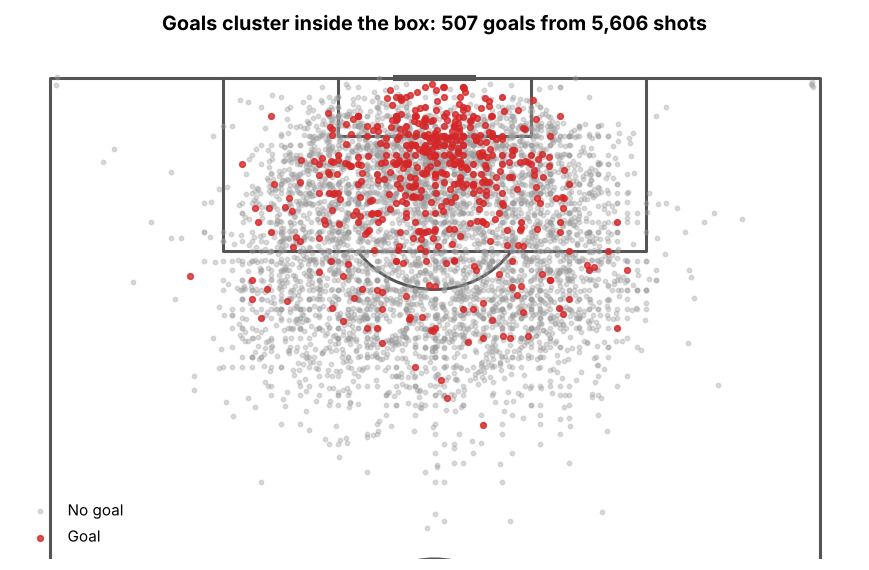

In [4]:
# Draw half a pitch and plot every shot: grey = no goal, red = goal
pitch = VerticalPitch(half=True, pitch_type="statsbomb", line_color="#555", pad_bottom=-10)
fig, ax = pitch.draw(figsize=(8, 6))

misses = shots[shots["goal"] == 0]
goals  = shots[shots["goal"] == 1]
pitch.scatter(misses["x"], misses["y"], s=8,  color=MISS_COLOR, alpha=0.35, ax=ax, label="No goal")
pitch.scatter(goals["x"],  goals["y"],  s=14, color=GOAL_COLOR, alpha=0.8,  ax=ax, label="Goal")

ax.legend(loc="lower left", frameon=False)
ax.set_title(f"Goals cluster inside the box: {len(goals)} goals from {len(shots):,} shots",
             fontsize=13, fontweight="bold")
plt.show()

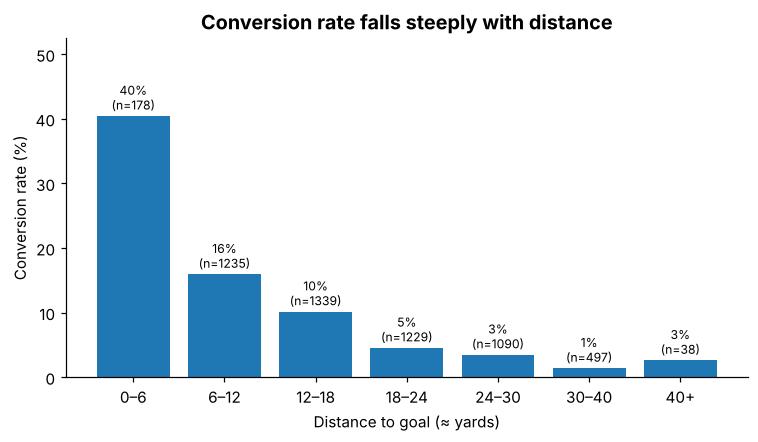

In [5]:
# Group shots into distance bands and calculate the goal rate in each band
bins   = [0, 6, 12, 18, 24, 30, 40, 100]
labels = ["0–6", "6–12", "12–18", "18–24", "24–30", "30–40", "40+"]
shots["distance_band"] = pd.cut(shots["distance"], bins=bins, labels=labels)

by_distance = shots.groupby("distance_band", observed=True)["goal"].agg(["mean", "size"])
# "mean" of a 0/1 column = conversion rate; "size" = number of shots

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_distance.index.astype(str), by_distance["mean"] * 100, color=ACCENT)

# Write the rate and sample size above each bar
for i, (rate, n) in enumerate(zip(by_distance["mean"], by_distance["size"])):
    ax.text(i, rate * 100 + 1, f"{rate:.0%}\n(n={n})", ha="center", fontsize=8)

ax.set_xlabel("Distance to goal (≈ yards)")
ax.set_ylabel("Conversion rate (%)")
ax.set_title("Conversion rate falls steeply with distance", fontsize=13, fontweight="bold")
ax.set_ylim(0, by_distance["mean"].max() * 100 + 12)
plt.show()

## 5. Train the model

### Why logistic regression?
The target is yes/no (goal or not), and we want a **probability** between 0 and 1. Logistic regression gives exactly that, it is easy to explain, and each feature gets a coefficient we can interpret.

### Why split by tournament?
If shots from the same tournament appeared in both training and testing, the test would be too easy. Training on three tournaments and testing on the unseen World Cup 2022 mimics real use: build a model on the past, apply it to new matches.

In [6]:
train = shots[shots["tournament"] != "WC 2022"]          # WC 2018, Euro 2020, Euro 2024
test  = shots[shots["tournament"] == "WC 2022"].copy()   # held out until the end

print(f"Training shots: {len(train):,} | Test shots (WC 2022): {len(test):,}")

model = LogisticRegression(max_iter=1000)   # max_iter: give the solver enough steps to finish
model.fit(train[FEATURES], train["goal"])   # learn from the training shots

# predict_proba returns [P(no goal), P(goal)] for each shot; column 1 is the xG
test["xg"] = model.predict_proba(test[FEATURES])[:, 1]

Training shots: 4,176 | Test shots (WC 2022): 1,430


### Reading the coefficients
A coefficient is hard to read directly, so we convert it to an **odds ratio** with `exp(coefficient)`:
- **Above 1**: the feature increases the chance of scoring (e.g. 2.6 = odds are 2.6 times higher).
- **Below 1**: it decreases the chance (e.g. 0.5 = odds are halved).

For distance and angle, the ratio is per one extra yard or one extra degree, with all other features held the same.

In [7]:
coefficients = pd.DataFrame({
    "feature":     FEATURES,
    "coefficient": model.coef_[0],
})
coefficients["odds_ratio"] = np.exp(coefficients["coefficient"])
coefficients.sort_values("odds_ratio", ascending=False).round(3).reset_index(drop=True)

,feature,coefficient,odds_ratio
0,shot_one_on_one,0.968,2.633
1,free_kick,0.626,1.870
2,shot_open_goal,0.613,1.845
3,counter,0.449,1.567
4,shot_first_time,0.125,1.133
5,angle_deg,0.028,1.028
6,distance,-0.071,0.931
7,set_piece,-0.432,0.649
8,under_pressure,-0.520,0.594
9,header,-0.646,0.524


## 6. Evaluate on World Cup 2022

### Metrics (all on shots the model has never seen)
- **Log loss** (lower is better): punishes confident wrong predictions. The main metric for probability models.
- **ROC AUC** (higher is better, 0.5 = random guessing, 1 = perfect): how well the model ranks goals above misses.
- **Brier score** (lower is better): average squared difference between the predicted probability and what happened.

### What we compare against
- **Naive baseline**: gives every shot the same xG (the average goal rate). Any useful model must beat this.
- **Gradient boosting**: a more complex tree-based model. Does extra complexity help?
- **StatsBomb xG**: the professional model, which also uses defender and goalkeeper positions.

In [8]:
# Train a more complex model on the same data, for comparison
boost = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                       max_iter=200, random_state=42)
boost.fit(train[FEATURES], train["goal"])

y_true = test["goal"]

# Predicted probability of a goal for every test shot, from each approach
predictions = {
    "Naive baseline":             np.full(len(test), train["goal"].mean()),
    "Logistic regression (ours)": test["xg"],
    "Gradient boosting":          boost.predict_proba(test[FEATURES])[:, 1],
    "StatsBomb xG (benchmark)":   test["shot_statsbomb_xg"],
}

rows = []
for name, p in predictions.items():
    rows.append({
        "model":        name,
        "Log loss":     log_loss(y_true, p),
        # AUC is undefined when every prediction is identical, so the baseline gets 0.5
        "ROC AUC":      roc_auc_score(y_true, p) if p.std() > 0 else 0.5,
        "Brier score":  brier_score_loss(y_true, p),
        "Total xG":     p.sum(),          # predicted number of goals in the tournament
        "Actual goals": y_true.sum(),
    })

pd.DataFrame(rows).set_index("model").round(3)

,Log loss,ROC AUC,Brier score,Total xG,Actual goals
model,,,,,
Naive baseline,0.341,0.500,0.095,121.564,152
Logistic regression (ours),0.285,0.777,0.081,133.249,152
Gradient boosting,0.290,0.767,0.082,131.036,152
StatsBomb xG (benchmark),0.267,0.815,0.076,137.878,152


### Calibration: can the probabilities be trusted?
If the model says 0.20 for a group of shots, about 20% of them should be goals. The chart groups shots by predicted xG and plots the real goal rate. Points close to the dashed line mean the probabilities are honest.

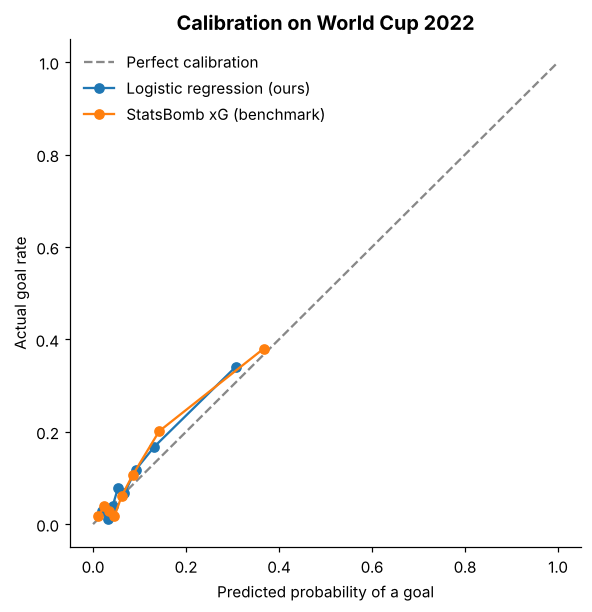

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "--", color="#888", label="Perfect calibration")

for name, color in [("Logistic regression (ours)", ACCENT), ("StatsBomb xG (benchmark)", "#ff7f0e")]:
    # Split shots into 8 equal-sized groups by predicted xG; compare predicted vs actual rate
    actual_rate, predicted_rate = calibration_curve(y_true, predictions[name],
                                                    n_bins=8, strategy="quantile")
    ax.plot(predicted_rate, actual_rate, "o-", color=color, label=name)

ax.set_xlabel("Predicted probability of a goal")
ax.set_ylabel("Actual goal rate")
ax.set_title("Calibration on World Cup 2022", fontsize=13, fontweight="bold")
ax.legend(frameon=False)
plt.show()

## 7. Who beat their xG at the 2022 World Cup?
For each player: add up real goals and xG. **Goals minus xG** above 0 means they scored more than an average finisher would have from the same chances.

Players with fewer than 8 shots are left out, because tiny samples give extreme, meaningless numbers.

In [10]:
MIN_SHOTS = 8

players = (test.groupby(["player", "team"])
               .agg(shots=("goal", "size"),    # number of shots
                    goals=("goal", "sum"),     # number of goals
                    xg=("xg", "sum"))          # total expected goals
               .reset_index())

players = players[players["shots"] >= MIN_SHOTS]
players["goals_minus_xg"] = players["goals"] - players["xg"]
players = players.sort_values("goals_minus_xg", ascending=False)

# Top 8 over-performers and bottom 8 under-performers
top_and_bottom = pd.concat([players.head(8), players.tail(8)])
top_and_bottom.round(2).reset_index(drop=True)

,player,team,shots,goals,xg,goals_minus_xg
0,Kylian Mbappé Lottin,France,29,6,2.94,3.06
1,Julián Álvarez,Argentina,11,4,1.88,2.12
2,Álvaro Borja Morata Martín,Spain,8,3,0.97,2.03
3,Marcus Rashford,England,11,3,0.99,2.01
4,Olivier Giroud,France,17,4,2.27,1.73
5,Richarlison de Andrade,Brazil,8,3,1.29,1.71
6,Mohammed Kudus,Ghana,8,2,0.61,1.39
7,Gue-Sung Cho,South Korea,8,2,1.00,1.00
8,Ousmane Dembélé,France,8,0,0.55,-0.55
9,Raphael Dias Belloli,Brazil,8,0,0.62,-0.62


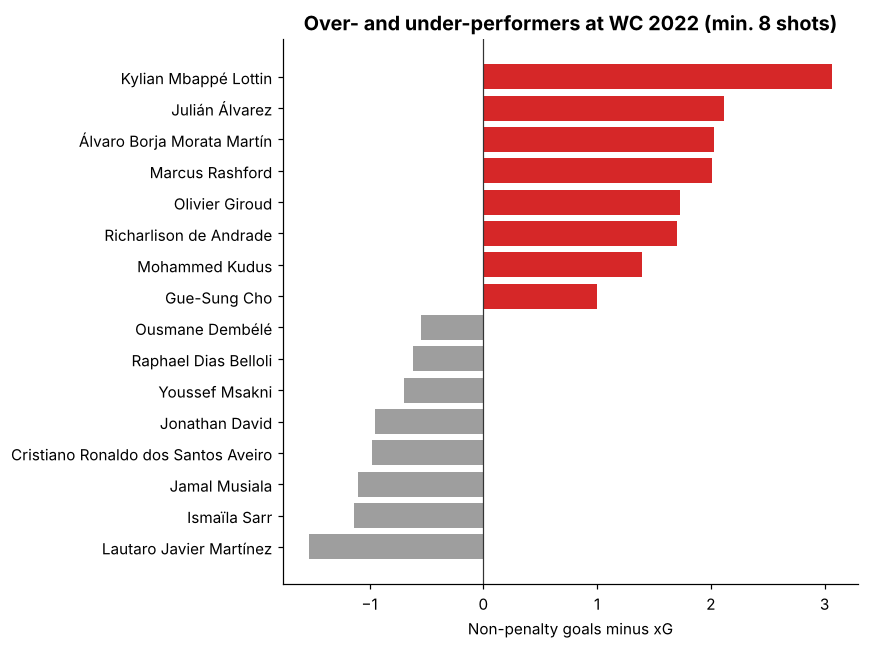

In [11]:
plot_data = top_and_bottom.sort_values("goals_minus_xg")
bar_colors = [GOAL_COLOR if v > 0 else MISS_COLOR for v in plot_data["goals_minus_xg"]]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(plot_data["player"], plot_data["goals_minus_xg"], color=bar_colors)
ax.axvline(0, color="#333", lw=0.8)   # zero line: scored exactly as expected
ax.set_xlabel("Non-penalty goals minus xG")
ax.set_title(f"Over- and under-performers at WC 2022 (min. {MIN_SHOTS} shots)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### Shot map of the biggest over-performer
Each circle is one shot. Bigger circle = higher xG (better chance). Red = goal.

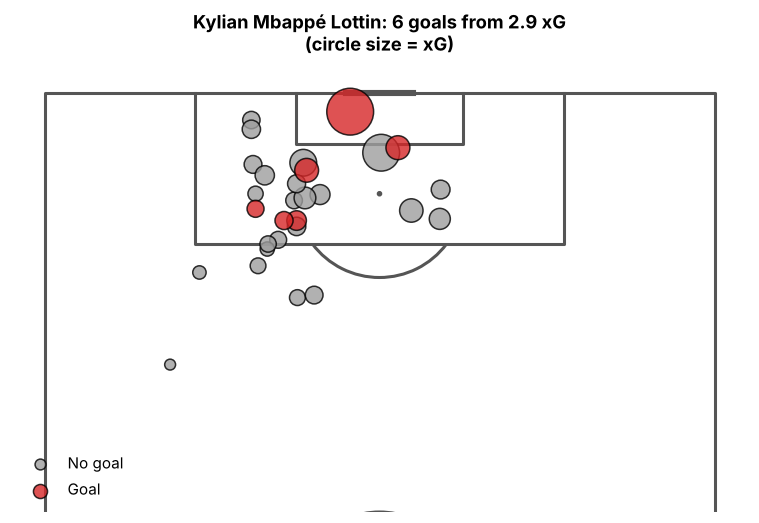

In [12]:
best = players.iloc[0]                                  # first row = highest goals minus xG
best_shots = test[test["player"] == best["player"]]

pitch = VerticalPitch(half=True, pitch_type="statsbomb", line_color="#555", pad_bottom=-10)
fig, ax = pitch.draw(figsize=(7, 6))

for scored, color, label in [(0, MISS_COLOR, "No goal"), (1, GOAL_COLOR, "Goal")]:
    s = best_shots[best_shots["goal"] == scored]
    pitch.scatter(s["x"], s["y"],
                  s=s["xg"] * 1500 + 40,               # circle size grows with xG
                  color=color, edgecolors="black", alpha=0.8, ax=ax, label=label)

ax.legend(loc="lower left", frameon=False, markerscale=0.4)
ax.set_title(f"{best['player']}: {int(best['goals'])} goals from {best['xg']:.1f} xG\n(circle size = xG)",
             fontsize=12, fontweight="bold")
plt.show()

## 8. Findings

**1. Simple features capture most of the signal.** With ten features, the logistic regression cut log loss by about 16% compared with the naive baseline (0.285 vs 0.341) and reached a ROC AUC of 0.78 on a tournament it never saw. StatsBomb's professional model reaches 0.82, and much of that gap comes from information this model doesn't have, such as goalkeeper and defender positions.

**2. Extra complexity did not help.** Gradient boosting did slightly *worse* (log loss 0.290 vs 0.285). With about 4,000 training shots, the simpler model generalises better and is much easier to explain.

**3. The coefficients match football intuition.** Each extra yard of distance cuts the odds of scoring by about 7%. Headers have about half the odds of a similar shot with the foot, shots under pressure about 40% lower odds, and one-on-ones about 2.6 times higher odds.

**4. World Cup 2022 had unusually good finishing.** Non-penalty shots were scored 10.6% of the time, against about 8.5% in the training tournaments. The model predicted 133 goals against 152 real ones. StatsBomb's model (138) shows the same gap, which suggests the finishing really was above normal, not just a flaw in this model.

**5. Mbappé was the standout finisher**, with 6 non-penalty goals from about 2.9 xG. Lautaro Martínez had the biggest shortfall (0 goals from about 1.5 xG).

**Limitation:** with only 8–30 shots per player, goals minus xG is very noisy. One tournament says little about true finishing skill, and research suggests finishing over-performance is only weakly repeated from one season to the next. These rankings describe what happened, not who is a better finisher.

**Next steps:** add freeze-frame features (defenders between shooter and goal, goalkeeper position), model penalties separately, and test whether over-performing in one tournament predicts the next.